# Regressão linear simples na evolução da apuração — Presidente 2026 (1º turno)

> **Base de cálculo: somente votos válidos.** Todas as fórmulas, regressões e predições deste notebook usam apenas os **votos válidos**, ou seja, os votos dados a candidatos. Brancos, nulos e abstenções não entram em nenhum cálculo. É a mesma base que o TSE usa para definir o resultado da eleição.

Este notebook usa o histórico da apuração divulgado pelo G1 (04 e 05/10/2026) para ajustar uma **regressão linear simples**:

- **x** = `pct_urnas_apuradas` (percentual de urnas apuradas no momento do snapshot)
- **y** = percentual de votos válidos do candidato

Analisamos dois candidatos: **Flávio Bolsonaro**, que terminou em primeiro lugar, e **Lula**, o segundo colocado.

> **Observação metodológica.** A evolução da apuração não é linear: a ordem em que as urnas chegam depende da região (capitais e Sul/Sudeste costumam vir antes, Norte/Nordeste depois), então a curva muda de inclinação ao longo da noite. Mesmo assim, o objetivo aqui é **acadêmico**: aplicar e interpretar a regressão linear simples passo a passo, e discutir onde ela funciona e onde falha.

## 1. Dependências

O `.venv` do projeto já tem `pandas` e `numpy`. Para os gráficos e para conferir o ajuste com uma biblioteca pronta, precisamos de `matplotlib` e `scikit-learn`. Rode a célula abaixo uma vez (depois pode comentá-la).

In [1]:
%pip install -q matplotlib scikit-learn
%pip install -q pandas numpy
%pip install jinja2

In [2]:
import unicodedata
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. Carregando os dados

O CSV "largo" tem uma linha por snapshot da apuração e uma coluna `pct_<NOME>` e `votos_<NOME>` por candidato. Os nomes das colunas têm espaços e acentos (por exemplo `pct_FLAVIO BOLSONARO`), o que é incômodo no código. Por isso **sanitizamos os nomes só aqui dentro do notebook**: minúsculas, sem acento e com `_` no lugar de espaços. O arquivo original não é alterado.

In [3]:
CAMINHO_CSV = "../data/processed/apuracao_largo.csv"

def sanitizar(nome: str) -> str:
    """'pct_FLAVIO BOLSONARO' -> 'pct_flavio_bolsonaro'"""
    sem_acento = unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^0-9a-z]+", "_", sem_acento.lower()).strip("_")

bruto = pd.read_csv(CAMINHO_CSV, parse_dates=["datetime"])
bruto.columns = [sanitizar(c) for c in bruto.columns]

print(f"{len(bruto)} snapshots, {bruto.shape[1]} colunas")
bruto.columns.tolist()

383 snapshots, 32 colunas


['datetime',
 'pct_urnas_apuradas',
 'pct_brancos',
 'pct_nulos',
 'pct_abstencao',
 'situacao',
 'pct_lula',
 'votos_lula',
 'pct_renan_santos',
 'votos_renan_santos',
 'pct_hertz_dias',
 'votos_hertz_dias',
 'pct_edmilson_costa',
 'votos_edmilson_costa',
 'pct_flavio_bolsonaro',
 'votos_flavio_bolsonaro',
 'pct_clariana_barao',
 'votos_clariana_barao',
 'pct_leonardo_avalanche',
 'votos_leonardo_avalanche',
 'pct_rui_costa_pimenta',
 'votos_rui_costa_pimenta',
 'pct_zema',
 'votos_zema',
 'pct_veterinario_wilson_grassi',
 'votos_veterinario_wilson_grassi',
 'pct_ronaldo_caiado',
 'votos_ronaldo_caiado',
 'pct_escritor_augusto_cury',
 'votos_escritor_augusto_cury',
 'pct_samara',
 'votos_samara']

### Base de cálculo: somente votos válidos

Votos válidos são os votos dados a candidatos, **sem brancos e nulos** (as abstenções nem chegam a ser votos). É a mesma base usada pelo TSE para decidir a eleição: vence no 1º turno quem tiver mais de 50% dos válidos.

As colunas `pct_<candidato>` do G1 já são percentuais dos válidos, mas vêm arredondadas em 2 casas. Para deixar a base explícita e ganhar precisão, **recalculamos** todos os percentuais a partir das colunas `votos_<candidato>`:

$$\text{pct}_c = 100 \cdot \frac{\text{votos}_c}{\sum_{k} \text{votos}_k}$$

e descartamos as colunas de brancos, nulos e abstenção, que não entram em nenhuma fórmula do notebook.

In [4]:
cols_votos = [c for c in bruto.columns if c.startswith("votos_")]
validos = bruto[cols_votos].fillna(0).sum(axis=1)
bruto["total_validos"] = validos

for col in cols_votos:
    pct_col = "pct_" + col.removeprefix("votos_")
    pct_g1 = bruto[pct_col]
    bruto[pct_col] = 100 * bruto[col] / validos
    # conferência: o valor recalculado bate com o do G1 até o arredondamento
    assert (bruto[pct_col] - pct_g1).abs().fillna(0).max() < 0.01, pct_col

bruto = bruto.drop(columns=["pct_brancos", "pct_nulos", "pct_abstencao"])
print("Percentuais recalculados sobre os votos válidos; brancos, nulos e abstenção removidos.")
print(f"Votos válidos no snapshot final: {bruto['total_validos'].iloc[-1]:,.0f}")

Percentuais recalculados sobre os votos válidos; brancos, nulos e abstenção removidos.
Votos válidos no snapshot final: 119,300,788


Ficamos só com as colunas que interessam. Também removemos snapshots repetidos com o mesmo `pct_urnas_apuradas` (por exemplo, o 100% "Parcial" e o 100% "Final" aparecem duas vezes), mantendo o último de cada valor, para que nenhum ponto pese em dobro no ajuste.

In [5]:
COL_X = "pct_urnas_apuradas"
CANDIDATOS = {
    "Flávio Bolsonaro": "pct_flavio_bolsonaro",
    "Lula": "pct_lula",
}
CORES = {"Flávio Bolsonaro": "#1f5fbf", "Lula": "#c8102e"}

df = (
    bruto[["datetime", COL_X, *CANDIDATOS.values()]]
    .dropna()
    .sort_values("datetime")
    .drop_duplicates(subset=COL_X, keep="last")
    .reset_index(drop=True)
)

print(f"{len(df)} pontos após remover duplicados")
df.describe().round(2)

247 pontos após remover duplicados


,datetime,pct_urnas_apuradas,pct_flavio_bolsonaro,pct_lula
count,247,247.00,247.00,247.00
mean,2026-10-04 20:37:01.955465,80.30,47.96,44.06
min,2026-10-04 17:21:16,1.23,47.03,40.66
25%,2026-10-04 20:18:26.500000,90.28,47.16,43.97
50%,2026-10-04 20:53:27,95.78,47.57,44.52
75%,2026-10-04 21:28:17.500000,99.34,48.05,45.01
max,2026-10-05 12:51:05,100.00,51.22,45.16
std,NaN,34.04,1.13,1.32


### Resultado final (o "gabarito")

O último snapshot, com 100% das urnas apuradas, é o resultado oficial. Vamos usá-lo para avaliar as previsões da regressão.

In [6]:
final = df.iloc[-1]
RESULTADO_FINAL = {nome: final[col] for nome, col in CANDIDATOS.items()}
print(f"Urnas apuradas: {final[COL_X]}%")
for nome, pct in RESULTADO_FINAL.items():
    print(f"  {nome}: {pct:.2f}% dos votos válidos")

Urnas apuradas: 100.0%
  Flávio Bolsonaro: 47.03% dos votos válidos
  Lula: 45.16% dos votos válidos


## 3. Visualizando os dados

Antes de ajustar qualquer modelo, olhamos o gráfico de dispersão de **x** (urnas apuradas) contra **y** (percentual do candidato).

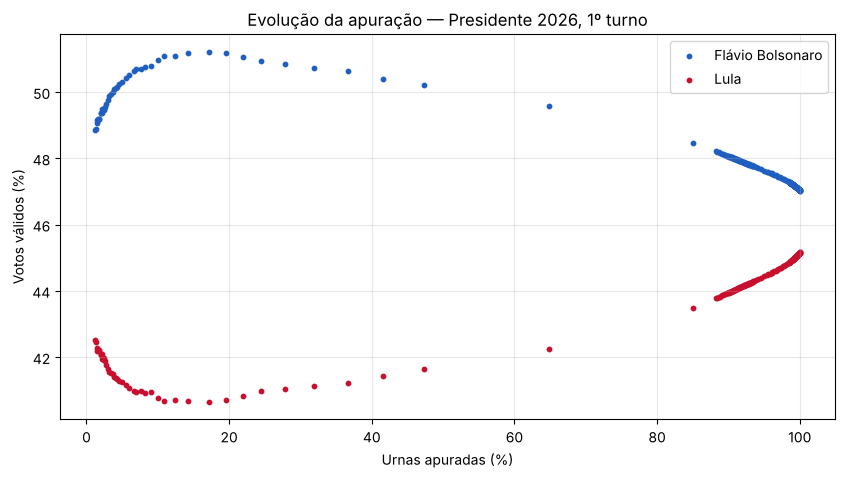

In [7]:
fig, ax = plt.subplots()
for nome, col in CANDIDATOS.items():
    ax.scatter(df[COL_X], df[col], s=10, color=CORES[nome], label=nome)
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Votos válidos (%)")
ax.set_title("Evolução da apuração — Presidente 2026, 1º turno")
ax.legend()
plt.show()

Já dá para ver que Flávio começa mais alto e cai, enquanto Lula começa mais baixo e sobe, e que as curvas se curvam no final. A reta vai capturar a **tendência média**, não o formato exato.

## 4. Regressão linear simples: a teoria

O modelo é

$$\hat{y} = \beta_0 + \beta_1 x$$

em que $\beta_0$ é o intercepto (valor previsto quando $x = 0$) e $\beta_1$ é a inclinação (quanto $y$ muda, em pontos percentuais, a cada 1 ponto percentual a mais de urnas apuradas).

Pelo método dos **mínimos quadrados ordinários**, os coeficientes que minimizam $\sum (y_i - \hat{y}_i)^2$ são

$$\beta_1 = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2}, \qquad \beta_0 = \bar{y} - \beta_1 \bar{x}$$

E o coeficiente de determinação, que mede a fração da variância de $y$ explicada pela reta, é

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

Vamos implementar essas fórmulas "na mão" com `numpy` e depois conferir com o `scikit-learn`.

In [8]:
def ajustar_mmq(x, y):
    """Mínimos quadrados ordinários pelas fórmulas fechadas. Retorna (beta0, beta1)."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_med, y_med = x.mean(), y.mean()
    beta1 = np.sum((x - x_med) * (y - y_med)) / np.sum((x - x_med) ** 2)
    beta0 = y_med - beta1 * x_med
    return beta0, beta1

def r2(y, y_prev):
    y = np.asarray(y, dtype=float)
    return 1 - np.sum((y - y_prev) ** 2) / np.sum((y - y.mean()) ** 2)

## 5. Flávio Bolsonaro (1º colocado)

### 5.1 Ajuste com as fórmulas

In [9]:
x = df[COL_X].to_numpy()
y_flavio = df[CANDIDATOS["Flávio Bolsonaro"]].to_numpy()

b0_f, b1_f = ajustar_mmq(x, y_flavio)
y_prev_f = b0_f + b1_f * x

print(f"Intercepto (β0): {b0_f:.4f}")
print(f"Inclinação (β1): {b1_f:.6f}")
print(f"R²:              {r2(y_flavio, y_prev_f):.4f}")
print(f"RMSE:            {np.sqrt(mean_squared_error(y_flavio, y_prev_f)):.4f} p.p.")
print()
print(f"Equação: ŷ = {b0_f:.3f} {'+' if b1_f >= 0 else '-'} {abs(b1_f):.5f} · x")

Intercepto (β0): 50.3665
Inclinação (β1): -0.029972
R²:              0.8171
RMSE:            0.4817 p.p.

Equação: ŷ = 50.366 - 0.02997 · x


### 5.2 Conferindo com o scikit-learn

O `LinearRegression` espera `X` como matriz (n linhas × 1 coluna), por isso o `reshape(-1, 1)`. Os coeficientes devem bater com os calculados acima.

In [10]:
modelo_f = LinearRegression().fit(x.reshape(-1, 1), y_flavio)
print(f"sklearn β0 = {modelo_f.intercept_:.4f}   β1 = {modelo_f.coef_[0]:.6f}")
print(f"sklearn R² = {modelo_f.score(x.reshape(-1, 1), y_flavio):.4f}")
assert np.isclose(modelo_f.intercept_, b0_f) and np.isclose(modelo_f.coef_[0], b1_f)
print("Coeficientes idênticos aos das fórmulas ✔")

sklearn β0 = 50.3665   β1 = -0.029972
sklearn R² = 0.8171
Coeficientes idênticos aos das fórmulas ✔


### 5.3 Interpretação

- **β1 negativo** significa que, em média, a cada 1 p.p. a mais de urnas apuradas o percentual de Flávio caiu |β1| p.p.: as urnas que chegaram depois eram menos favoráveis a ele.
- **β0** é o percentual que a reta "prevê" com 0% das urnas. Não tem significado real (não existe resultado com zero urnas), é só onde a reta corta o eixo.
- **R²** diz quanto da variação do percentual ao longo da noite a reta explica.

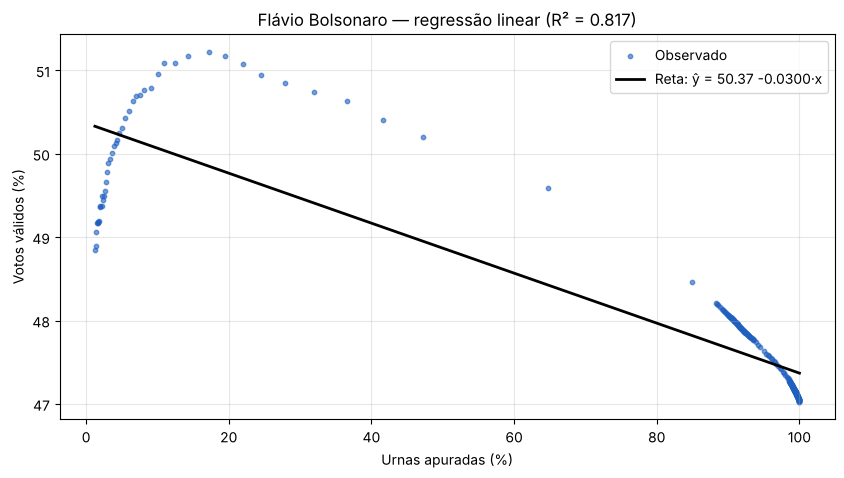

In [11]:
fig, ax = plt.subplots()
ax.scatter(x, y_flavio, s=10, color=CORES["Flávio Bolsonaro"], alpha=0.6, label="Observado")
ax.plot(x, y_prev_f, color="black", lw=2, label=f"Reta: ŷ = {b0_f:.2f} {b1_f:+.4f}·x")
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Votos válidos (%)")
ax.set_title(f"Flávio Bolsonaro — regressão linear (R² = {r2(y_flavio, y_prev_f):.3f})")
ax.legend()
plt.show()

### 5.4 Extrapolando para 100% das urnas

Substituímos x = 100 na equação e comparamos com o resultado oficial. Aqui o modelo usou **todos** os pontos, inclusive os do fim da apuração, então é um teste fácil.

In [12]:
prev_100_f = b0_f + b1_f * 100
print(f"Previsão da reta em 100%: {prev_100_f:.2f}%")
print(f"Resultado oficial:        {RESULTADO_FINAL['Flávio Bolsonaro']:.2f}%")
print(f"Erro:                     {prev_100_f - RESULTADO_FINAL['Flávio Bolsonaro']:+.2f} p.p.")

Previsão da reta em 100%: 47.37%
Resultado oficial:        47.03%
Erro:                     +0.34 p.p.


### 5.5 Resíduos

Os resíduos ($y_i - \hat{y}_i$) mostram o que a reta não captura. Se o modelo linear fosse adequado, eles se espalhariam aleatoriamente em torno de zero. Um padrão em forma de curva indica que a relação real não é linear.

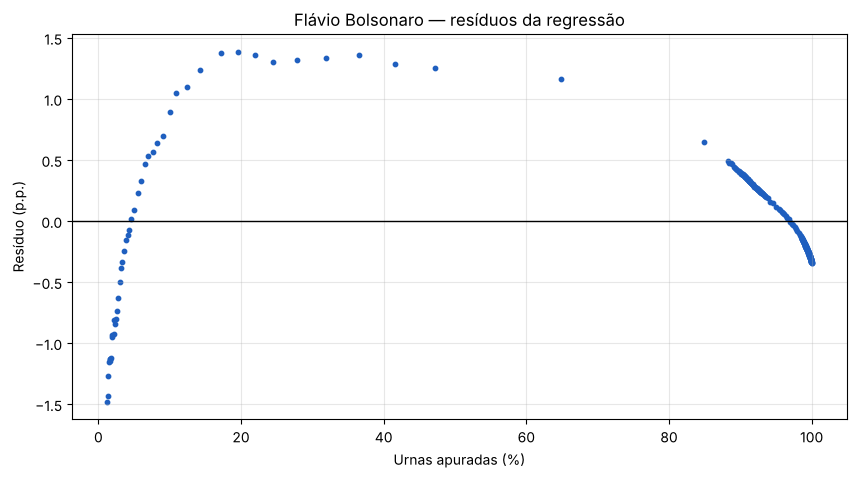

In [13]:
fig, ax = plt.subplots()
ax.scatter(x, y_flavio - y_prev_f, s=10, color=CORES["Flávio Bolsonaro"])
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Resíduo (p.p.)")
ax.set_title("Flávio Bolsonaro — resíduos da regressão")
plt.show()

## 6. Lula (2º colocado)

Repetimos exatamente os mesmos passos para Lula, agora usando uma função para não duplicar código.

In [14]:
def analisar(nome, x, y):
    b0, b1 = ajustar_mmq(x, y)
    y_prev = b0 + b1 * x
    prev_100 = b0 + b1 * 100
    return {
        "candidato": nome,
        "beta0": b0,
        "beta1": b1,
        "R2": r2(y, y_prev),
        "RMSE": np.sqrt(mean_squared_error(y, y_prev)),
        "previsto_100": prev_100,
        "real_100": RESULTADO_FINAL[nome],
        "erro_pp": prev_100 - RESULTADO_FINAL[nome],
    }

y_lula = df[CANDIDATOS["Lula"]].to_numpy()
res_lula = analisar("Lula", x, y_lula)
b0_l, b1_l = res_lula["beta0"], res_lula["beta1"]

print(f"Equação: ŷ = {b0_l:.3f} {'+' if b1_l >= 0 else '-'} {abs(b1_l):.5f} · x")
print(f"R² = {res_lula['R2']:.4f}   RMSE = {res_lula['RMSE']:.4f} p.p.")
print(f"Previsão em 100%: {res_lula['previsto_100']:.2f}%  |  oficial: {res_lula['real_100']:.2f}%  |  erro: {res_lula['erro_pp']:+.2f} p.p.")

Equação: ŷ = 41.136 + 0.03637 · x
R² = 0.8789   RMSE = 0.4585 p.p.
Previsão em 100%: 44.77%  |  oficial: 45.16%  |  erro: -0.39 p.p.


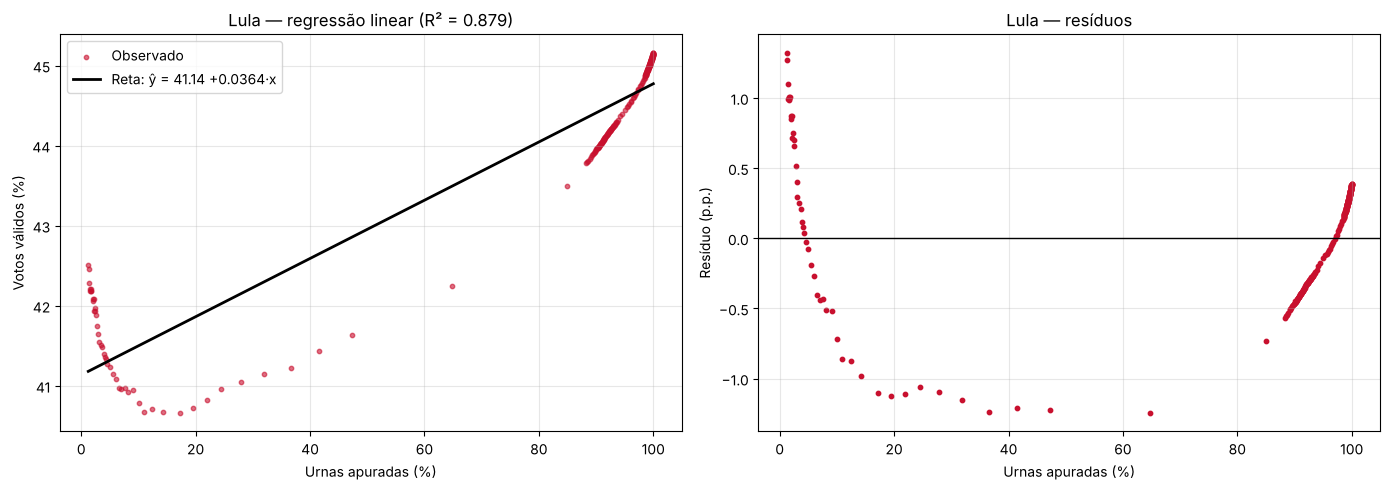

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.scatter(x, y_lula, s=10, color=CORES["Lula"], alpha=0.6, label="Observado")
ax.plot(x, b0_l + b1_l * x, color="black", lw=2, label=f"Reta: ŷ = {b0_l:.2f} {b1_l:+.4f}·x")
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Votos válidos (%)")
ax.set_title(f"Lula — regressão linear (R² = {res_lula['R2']:.3f})")
ax.legend()

ax = axes[1]
ax.scatter(x, y_lula - (b0_l + b1_l * x), s=10, color=CORES["Lula"])
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Resíduo (p.p.)")
ax.set_title("Lula — resíduos")

plt.tight_layout()
plt.show()

## 7. Comparando os dois candidatos

In [16]:
resumo = pd.DataFrame([analisar(nome, x, df[col].to_numpy()) for nome, col in CANDIDATOS.items()])
resumo.set_index("candidato").round(4)

,beta0,beta1,R2,RMSE,previsto_100,real_100,erro_pp
candidato,,,,,,,
Flávio Bolsonaro,50.3665,-0.0300,0.8171,0.4817,47.3693,47.0278,0.3415
Lula,41.1361,0.0364,0.8789,0.4585,44.7726,45.1628,-0.3902


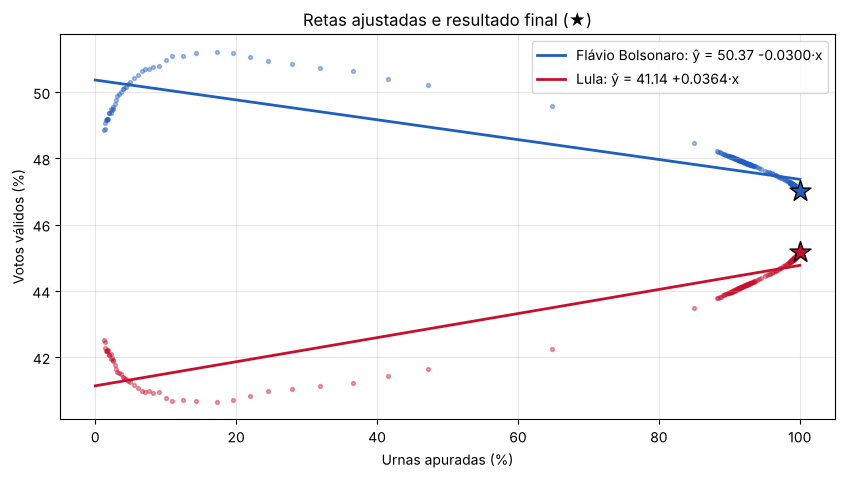

In [17]:
fig, ax = plt.subplots()
for nome, col in CANDIDATOS.items():
    b0, b1 = ajustar_mmq(x, df[col])
    ax.scatter(x, df[col], s=8, color=CORES[nome], alpha=0.4)
    ax.plot([0, 100], [b0, b0 + b1 * 100], color=CORES[nome], lw=2, label=f"{nome}: ŷ = {b0:.2f} {b1:+.4f}·x")
    ax.scatter([100], [RESULTADO_FINAL[nome]], marker="*", s=250, color=CORES[nome], edgecolor="black", zorder=5)
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Votos válidos (%)")
ax.set_title("Retas ajustadas e resultado final (★)")
ax.legend()
plt.show()

## 8. Dá para prever o resultado no meio da apuração?

O teste mais interessante é **treinar só com o começo da apuração** e prever o resultado em 100%, como se estivéssemos na noite da eleição sem saber o final. Treinamos com os pontos até 30%, 40% e 50% das urnas apuradas e comparamos a previsão com o resultado oficial.

Como referência, comparamos também com o "modelo ingênuo": simplesmente usar o último percentual conhecido como previsão final.

In [18]:
CORTES = [30, 40, 50]

linhas = []
for corte in CORTES:
    treino = df[df[COL_X] <= corte]
    for nome, col in CANDIDATOS.items():
        b0, b1 = ajustar_mmq(treino[COL_X], treino[col])
        prev = b0 + b1 * 100
        ultimo = treino[col].iloc[-1]
        real = RESULTADO_FINAL[nome]
        linhas.append({
            "treino_ate_%": corte,
            "candidato": nome,
            "n_pontos": len(treino),
            "beta1": b1,
            "previsto_100": prev,
            "ultimo_valor": ultimo,
            "real_100": real,
            "erro_reta_pp": prev - real,
            "erro_ingenuo_pp": ultimo - real,
        })

previsoes = pd.DataFrame(linhas)
previsoes.round(3)

,treino_ate_%,candidato,n_pontos,beta1,previsto_100,ultimo_valor,real_100,erro_reta_pp,erro_ingenuo_pp
0,30,Flávio Bolsonaro,41,0.087,58.216,50.853,47.028,11.188,3.825
1,30,Lula,41,-0.062,35.706,41.052,45.163,-9.456,-4.110
2,40,Flávio Bolsonaro,43,0.058,55.476,50.633,47.028,8.449,3.605
3,40,Lula,43,-0.039,37.861,41.229,45.163,-7.302,-3.934
4,50,Flávio Bolsonaro,45,0.035,53.298,50.203,47.028,6.271,3.175
5,50,Lula,45,-0.021,39.552,41.631,45.163,-5.611,-3.531


Vale olhar também **quem a reta diz que ganha**: se a inclinação for forte o bastante, ela pode prever uma virada que não aconteceu (ou acertar uma que aconteceu).

In [19]:
for corte in CORTES:
    p = previsoes[previsoes["treino_ate_%"] == corte].set_index("candidato")["previsto_100"]
    lider = p.idxmax()
    print(f"Treino até {corte}%: Flávio {p['Flávio Bolsonaro']:.2f}% × Lula {p['Lula']:.2f}%  →  líder previsto: {lider}")
real_lider = max(RESULTADO_FINAL, key=RESULTADO_FINAL.get)
print(f"Resultado oficial: líder = {real_lider}")

Treino até 30%: Flávio 58.22% × Lula 35.71%  →  líder previsto: Flávio Bolsonaro
Treino até 40%: Flávio 55.48% × Lula 37.86%  →  líder previsto: Flávio Bolsonaro
Treino até 50%: Flávio 53.30% × Lula 39.55%  →  líder previsto: Flávio Bolsonaro
Resultado oficial: líder = Flávio Bolsonaro


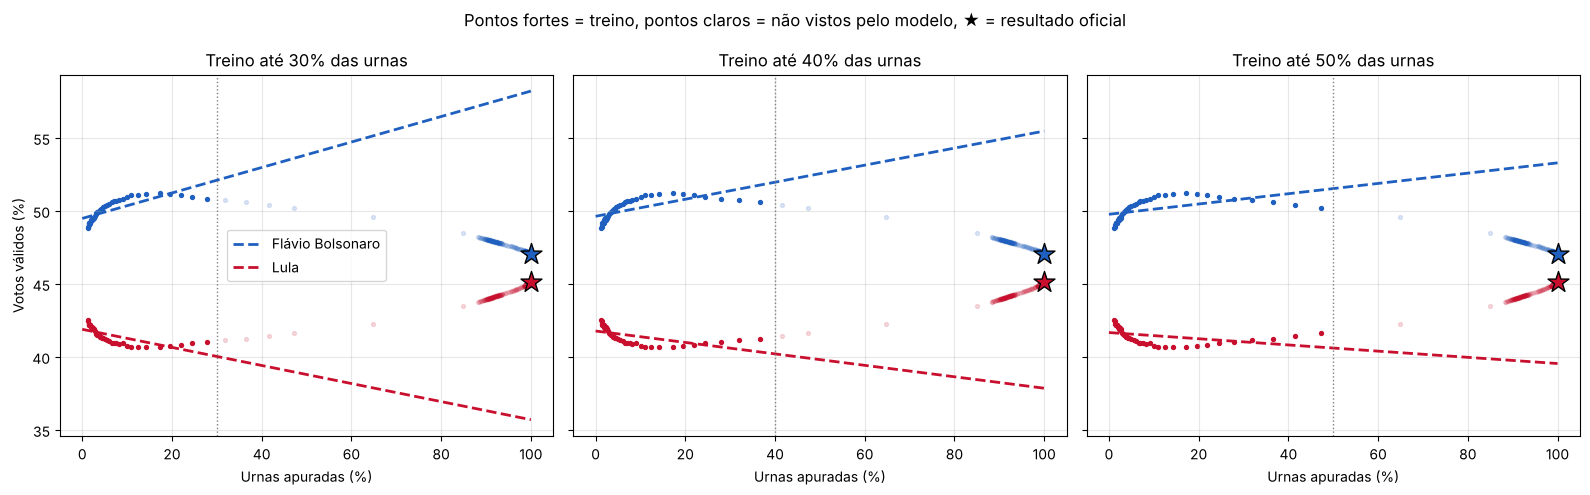

In [20]:
fig, axes = plt.subplots(1, len(CORTES), figsize=(16, 5), sharey=True)
for ax, corte in zip(axes, CORTES):
    treino = df[df[COL_X] <= corte]
    teste = df[df[COL_X] > corte]
    for nome, col in CANDIDATOS.items():
        b0, b1 = ajustar_mmq(treino[COL_X], treino[col])
        ax.scatter(treino[COL_X], treino[col], s=8, color=CORES[nome])
        ax.scatter(teste[COL_X], teste[col], s=8, color=CORES[nome], alpha=0.15)
        ax.plot([0, 100], [b0, b0 + b1 * 100], color=CORES[nome], lw=2, ls="--", label=nome)
        ax.scatter([100], [RESULTADO_FINAL[nome]], marker="*", s=250, color=CORES[nome], edgecolor="black", zorder=5)
    ax.axvline(corte, color="gray", ls=":", lw=1)
    ax.set_title(f"Treino até {corte}% das urnas")
    ax.set_xlabel("Urnas apuradas (%)")
axes[0].set_ylabel("Votos válidos (%)")
axes[0].legend()
plt.suptitle("Pontos fortes = treino, pontos claros = não vistos pelo modelo, ★ = resultado oficial")
plt.tight_layout()
plt.show()

## 9. Limitações

- **A relação não é linear.** O padrão curvo nos resíduos mostra que a inclinação muda ao longo da apuração. A reta resume a tendência média, mas erra sistematicamente em trechos específicos.
- **Os pontos não são independentes.** Cada snapshot é a soma acumulada dos anteriores mais algumas urnas novas, então pontos vizinhos são quase iguais. Isso viola a hipótese de independência dos erros, e medidas como erro padrão e p-valor ficariam otimistas demais.
- **A ordem de chegada das urnas não é aleatória.** A variação do percentual vem de *quais* regiões são apuradas em cada momento, algo que o x (percentual de urnas) não captura.
- **Os pontos estão concentrados no fim.** Metade dos snapshots tem mais de ~96% das urnas apuradas, porque o G1 atualiza com mais frequência no final. A reta ajustada com todos os dados é "puxada" por esse trecho, o que ajuda a extrapolação para 100% mas esconde o comportamento do começo.
- **Extrapolar é arriscado.** Prever 100% a partir de 30% significa usar a reta muito fora do intervalo de treino.

Mesmo com essas limitações, o exercício mostra bem como estimar, interpretar e avaliar uma regressão linear simples.

## 10. Conclusões

- **Inclinações.** Com todos os dados, a reta de Flávio tem β1 ≈ −0,030 (perde cerca de 0,3 p.p. a cada 10 p.p. de urnas apuradas) e a de Lula tem β1 ≈ +0,036. É o padrão clássico: as urnas que chegam primeiro favorecem um candidato e as últimas, o outro.
- **R².** Os ajustes explicam cerca de 82% (Flávio) e 88% (Lula) da variação do percentual. É alto, mas parte disso vem da concentração de pontos perto de 100%.
- **Extrapolação com todos os dados.** A reta prevê 47,37% para Flávio (real: 47,03%) e 44,77% para Lula (real: 45,16%), erros de menos de 0,4 p.p. Mas é um teste fácil, porque o modelo já "viu" o final.
- **Previsão no meio da apuração.** Treinando só até 30–50% das urnas, a inclinação tem **sinal oposto**: no começo Flávio ainda subia e Lula caía. A reta acerta o vencedor (Flávio), mas erra o percentual em 6 a 11 p.p., bem pior que o modelo ingênuo (3 a 4 p.p.). É a demonstração prática de que a curva não é linear e de que extrapolar uma tendência local é perigoso.

## 11. Predição

Nenhum candidato passou de 50% dos votos válidos, então haverá **2º turno entre Flávio Bolsonaro e Lula**. A pergunta deste capítulo é: *para onde vão os votos de quem ficou de fora?*

### 11.1 Votos da terceira via

Agrupamos os demais candidatos em cinco blocos: **Augusto Cury**, **Renan Santos**, **Caiado**, **Zema** e **Demais** (a soma de todos os outros candidatos fora Flávio e Lula). Usamos o snapshot final, com 100% das urnas.

In [21]:
TERCEIRA_VIA = {
    "Augusto Cury": "escritor_augusto_cury",
    "Renan Santos": "renan_santos",
    "Caiado": "ronaldo_caiado",
    "Zema": "zema",
}
FINALISTAS = {"Flávio Bolsonaro": "flavio_bolsonaro", "Lula": "lula"}

# "Demais" = todo candidato que não é finalista nem está na lista acima
todos = [c.removeprefix("votos_") for c in bruto.columns if c.startswith("votos_")]
DEMAIS = [c for c in todos if c not in TERCEIRA_VIA.values() and c not in FINALISTAS.values()]
print("Demais:", ", ".join(DEMAIS))

snap_final = bruto.sort_values("datetime").iloc[-1]
votos = lambda cols: sum(snap_final[f"votos_{c}"] for c in cols if pd.notna(snap_final[f"votos_{c}"]))
pct = lambda cols: sum(snap_final[f"pct_{c}"] for c in cols if pd.notna(snap_final[f"pct_{c}"]))

GRUPOS = {nome: [col] for nome, col in TERCEIRA_VIA.items()}
GRUPOS["Demais"] = DEMAIS

tabela_3via = pd.DataFrame(
    [{"grupo": g, "votos": int(votos(cols)), "pct_validos": pct(cols)} for g, cols in GRUPOS.items()]
).set_index("grupo")
tabela_3via.loc["TOTAL 3ª via"] = tabela_3via.sum()
tabela_3via["votos"] = tabela_3via["votos"].astype(int)
tabela_3via.round({"pct_validos": 2})

Demais: hertz_dias, edmilson_costa, clariana_barao, leonardo_avalanche, rui_costa_pimenta, veterinario_wilson_grassi, samara


,votos,pct_validos
grupo,,
Augusto Cury,3448569,2.89
Renan Santos,2675887,2.24
Caiado,2605148,2.18
Zema,326488,0.27
Demais,260655,0.22
TOTAL 3ª via,9316747,7.81


### 11.2 Percentual de transferência (editável)

Para cada bloco, escolha quanto (%) dos votos vai para Flávio e quanto vai para Lula. O que sobrar até 100% é considerado **branco, nulo ou abstenção** no 2º turno: esses votos **saem da conta**, porque o resultado é calculado só sobre os votos válidos (Flávio + Lula).

Começamos com **50% / 50%** para todos. Mude os números e rode as células seguintes novamente.

In [86]:
augusto_cury_to_flavio = 50
renan_santos_to_flavio = 50
caiado_to_flavio = 60
zema_to_flavio = 50
demais_to_flavio = 50

TRANSFERENCIA = {
    "Augusto Cury": {"flavio": augusto_cury_to_flavio, "lula": 100 - augusto_cury_to_flavio},
    "Renan Santos": {"flavio": renan_santos_to_flavio, "lula": 100 - renan_santos_to_flavio},
    "Caiado":       {"flavio": caiado_to_flavio,       "lula": 100 - caiado_to_flavio},
    "Zema":         {"flavio": zema_to_flavio,         "lula": 100 - zema_to_flavio},
    "Demais":       {"flavio": demais_to_flavio,       "lula": 100 - demais_to_flavio},
}

for grupo, t in TRANSFERENCIA.items():
    assert 0 <= t["flavio"] + t["lula"] <= 100, f"{grupo}: a soma passa de 100%"
    t["branco_nulo"] = 100 - t["flavio"] - t["lula"]

pd.DataFrame(TRANSFERENCIA).T.rename(columns={"flavio": "% Flávio", "lula": "% Lula", "branco_nulo": "% branco/nulo/abst."})

,% Flávio,% Lula,% branco/nulo/abst.
Augusto Cury,50,50,0
Renan Santos,50,50,0
Caiado,60,40,0
Zema,50,50,0
Demais,50,50,0


### 11.3 Simulação do 2º turno com o resultado real do 1º turno

Partimos dos votos que cada finalista teve no 1º turno e somamos a parte transferida de cada bloco. Supomos que os eleitores de Flávio e Lula repetem o voto. O percentual final é calculado sobre os **votos válidos do 2º turno**, ou seja, só os votos em Flávio ou Lula.

In [87]:
def simular_2turno(base_flavio, base_lula, grupos):
    """Recebe a base de cada finalista e o tamanho de cada bloco da 3ª via (em votos ou em %)."""
    flavio = base_flavio + sum(grupos[g] * TRANSFERENCIA[g]["flavio"] / 100 for g in grupos)
    lula = base_lula + sum(grupos[g] * TRANSFERENCIA[g]["lula"] / 100 for g in grupos)
    validos = flavio + lula
    return flavio, lula, 100 * flavio / validos, 100 * lula / validos

grupos_votos = tabela_3via["votos"].drop("TOTAL 3ª via").to_dict()
v_f, v_l, p_f, p_l = simular_2turno(
    snap_final["votos_flavio_bolsonaro"], snap_final["votos_lula"], grupos_votos
)
print(f"Flávio Bolsonaro: {v_f:,.0f} votos  ({p_f:.2f}% dos válidos)")
print(f"Lula:             {v_l:,.0f} votos  ({p_l:.2f}% dos válidos)")
print(f"Vencedor simulado: {'Flávio Bolsonaro' if p_f > p_l else 'Lula'}  (diferença de {abs(p_f - p_l):.2f} p.p.)")

Flávio Bolsonaro: 61,023,391 votos  (51.15% dos válidos)
Lula:             58,277,397 votos  (48.85% dos válidos)
Vencedor simulado: Flávio Bolsonaro  (diferença de 2.30 p.p.)


### 11.4 Usando a regressão linear na predição

Como encaixar a terceira via na regressão? Uma forma simples, que mantém o modelo **linear simples**, é ajustar uma reta para **cada bloco** da mesma forma que fizemos para Flávio e Lula:

1. Para cada série (Flávio, Lula, Cury, Renan, Caiado, Zema, Demais), ajustar $\hat{y} = \beta_0 + \beta_1 x$ usando só os snapshots até `CORTE_TREINO` % das urnas.
2. Extrapolar cada reta para x = 100 e obter o percentual previsto no 1º turno.
3. Aplicar a tabela de transferência sobre esses percentuais previstos para estimar o 2º turno.

Assim a predição do 2º turno vira uma função da regressão + das hipóteses de transferência. Com `CORTE_TREINO = 100` o modelo usa todos os dados; troque para 30, 40 ou 50 para simular uma previsão feita no meio da apuração.

In [88]:
CORTE_TREINO = 100

serie = lambda cols: bruto[[f"pct_{c}" for c in cols]].fillna(0).sum(axis=1)
SERIES = {"Flávio Bolsonaro": serie(["flavio_bolsonaro"]), "Lula": serie(["lula"])}
SERIES.update({g: serie(cols) for g, cols in GRUPOS.items()})

dados = pd.DataFrame({COL_X: bruto[COL_X], **SERIES}).drop_duplicates(subset=COL_X, keep="last")
treino = dados[dados[COL_X] <= CORTE_TREINO]

linhas = []
for nome in SERIES:
    b0, b1 = ajustar_mmq(treino[COL_X], treino[nome])
    linhas.append({"serie": nome, "beta0": b0, "beta1": b1, "previsto_100": b0 + b1 * 100,
                   "real_100": dados[nome].iloc[-1]})
retas = pd.DataFrame(linhas).set_index("serie")
retas["erro_pp"] = retas["previsto_100"] - retas["real_100"]
print(f"Treino com {len(treino)} pontos (até {CORTE_TREINO}% das urnas)")
retas.round(3)

Treino com 247 pontos (até 100% das urnas)


,beta0,beta1,previsto_100,real_100,erro_pp
serie,,,,,
Flávio Bolsonaro,50.366,-0.030,47.369,47.028,0.342
Lula,41.136,0.036,44.773,45.163,-0.390
Augusto Cury,3.044,-0.001,2.902,2.891,0.012
Renan Santos,2.402,-0.001,2.260,2.243,0.017
Caiado,2.399,-0.002,2.205,2.184,0.022
Zema,0.358,-0.001,0.274,0.274,-0.000
Demais,0.295,-0.001,0.217,0.218,-0.002


#### Equações da regressão de cada candidato

Antes de calcular o 2º turno, vamos escrever explicitamente a reta de cada série. Para cada candidato ou bloco $c$, o modelo é

$$\hat{y}_c(x) = \beta_{0,c} + \beta_{1,c} \cdot x$$

em que $x$ é o percentual de urnas apuradas e $\hat{y}_c$ é o percentual previsto dos **votos válidos**. Os coeficientes saem das mesmas fórmulas de mínimos quadrados da seção 4:

$$\beta_{1,c} = \frac{\sum (x_i - \bar{x})(y_{c,i} - \bar{y}_c)}{\sum (x_i - \bar{x})^2}, \qquad \beta_{0,c} = \bar{y}_c - \beta_{1,c} \bar{x}$$

A previsão para o fim da apuração é a reta avaliada em $x = 100$: $\hat{y}_c(100) = \beta_{0,c} + 100 \cdot \beta_{1,c}$.

In [89]:
print(f"Retas ajustadas com os snapshots até {CORTE_TREINO}% das urnas:\n")
for nome, r in retas.iterrows():
    sinal = "+" if r["beta1"] >= 0 else "-"
    print(f"{nome:<17} ŷ = {r['beta0']:7.4f} {sinal} {abs(r['beta1']):.6f} · x"
          f"   →  ŷ(100) = {r['beta0']:.4f} {sinal} {abs(r['beta1']) * 100:.4f} = {r['previsto_100']:.2f}%")

Retas ajustadas com os snapshots até 100% das urnas:

Flávio Bolsonaro  ŷ = 50.3665 - 0.029972 · x   →  ŷ(100) = 50.3665 - 2.9972 = 47.37%
Lula              ŷ = 41.1361 + 0.036365 · x   →  ŷ(100) = 41.1361 + 3.6365 = 44.77%
Augusto Cury      ŷ =  3.0437 - 0.001413 · x   →  ŷ(100) = 3.0437 - 0.1413 = 2.90%
Renan Santos      ŷ =  2.4024 - 0.001424 · x   →  ŷ(100) = 2.4024 - 0.1424 = 2.26%
Caiado            ŷ =  2.3991 - 0.001939 · x   →  ŷ(100) = 2.3991 - 0.1939 = 2.21%
Zema              ŷ =  0.3576 - 0.000841 · x   →  ŷ(100) = 0.3576 - 0.0841 = 0.27%
Demais            ŷ =  0.2945 - 0.000776 · x   →  ŷ(100) = 0.2945 - 0.0776 = 0.22%


#### Aplicando a transferência, passo a passo

**Fórmulas**

$$F_2 = \hat{y}_F(100) + \sum_{g} t_{F,g} \cdot \hat{y}_g(100), \qquad L_2 = \hat{y}_L(100) + \sum_{g} t_{L,g} \cdot \hat{y}_g(100)$$

$$\text{Flávio (\% válidos)} = 100 \cdot \frac{F_2}{F_2 + L_2}, \qquad \text{Lula (\% válidos)} = 100 \cdot \frac{L_2}{F_2 + L_2}$$

em que $g$ é cada bloco da 3ª via e $t_{F,g}$, $t_{L,g}$ são as frações transferidas para Flávio e para Lula (por exemplo, 80% = 0,80).

**O que essas fórmulas dizem, em palavras**

**A ideia em uma frase:** cada finalista começa com o percentual que a sua reta prevê para o fim do 1º turno e depois "herda" uma parte dos votos dos candidatos que ficaram de fora, conforme a tabela da seção 11.2.

**Passo 1. Ponto de partida.** Flávio e Lula começam com o valor das suas retas em 100% das urnas (calculado na célula anterior). Supomos que quem votou neles no 1º turno vota de novo no 2º.

**Passo 2. Votos herdados de cada bloco.** Para cada bloco da 3ª via, multiplicamos o tamanho dele pelo percentual que vai para cada finalista.
*Exemplo:* se a reta prevê que Caiado termina com 2,21% e 80% dos eleitores dele vão para Flávio, Flávio ganha 2,21 × 0,80 ≈ 1,77 ponto e Lula ganha 2,21 × 0,20 ≈ 0,44 ponto.

**Passo 3. Somar tudo.** O total de cada finalista é o ponto de partida mais tudo o que ele herdou de todos os blocos.

**Passo 4. Voltar para 100% dos válidos.** Se algum bloco tiver uma parte que vai para branco, nulo ou abstenção, essa parte **sai da conta**, e os dois totais deixam de somar 100. Por isso dividimos cada total pela soma dos dois.
*Exemplo:* se Flávio somar 52 pontos e Lula 46, os válidos do 2º turno são 52 + 46 = 98, e Flávio fica com 52 ÷ 98 = 53,06%. Quando toda a 3ª via é transferida (nada para branco/nulo), esse passo só corrige pequenos arredondamentos.

A célula abaixo mostra cada um desses passos com os números atuais.

In [90]:
prev = retas["previsto_100"]

# Passo 1: ponto de partida
partida_f, partida_l = prev["Flávio Bolsonaro"], prev["Lula"]
print("PASSO 1. Ponto de partida (reta em 100% das urnas)")
print(f"  Flávio Bolsonaro: {partida_f:.2f} pontos")
print(f"  Lula:             {partida_l:.2f} pontos\n")

# Passo 2: votos herdados de cada bloco
passo2 = pd.DataFrame([
    {
        "bloco": g,
        "tamanho previsto (%)": prev[g],
        "% p/ Flávio": TRANSFERENCIA[g]["flavio"],
        "pontos p/ Flávio": prev[g] * TRANSFERENCIA[g]["flavio"] / 100,
        "% p/ Lula": TRANSFERENCIA[g]["lula"],
        "pontos p/ Lula": prev[g] * TRANSFERENCIA[g]["lula"] / 100,
        "pontos p/ branco/nulo": prev[g] * TRANSFERENCIA[g]["branco_nulo"] / 100,
    }
    for g in GRUPOS
]).set_index("bloco")
passo2.loc["TOTAL"] = passo2.sum()
passo2.loc["TOTAL", ["% p/ Flávio", "% p/ Lula"]] = np.nan
print("PASSO 2. Votos herdados de cada bloco (tamanho × % de transferência)")
print(passo2.round(2).fillna("").to_string(), "\n")

# Passo 3: somar
herdado_f, herdado_l = passo2.loc["TOTAL", "pontos p/ Flávio"], passo2.loc["TOTAL", "pontos p/ Lula"]
F2, L2 = partida_f + herdado_f, partida_l + herdado_l
print("PASSO 3. Somar partida + herdados")
print(f"  Flávio: {partida_f:.2f} + {herdado_f:.2f} = {F2:.2f} pontos")
print(f"  Lula:   {partida_l:.2f} + {herdado_l:.2f} = {L2:.2f} pontos\n")

# Passo 4: voltar para 100% dos válidos
total = F2 + L2
print("PASSO 4. Dividir pela soma dos dois (só votos válidos)")
print(f"  Válidos no 2º turno: {F2:.2f} + {L2:.2f} = {total:.2f} pontos")
print(f"  Flávio: {F2:.2f} ÷ {total:.2f} = {100 * F2 / total:.2f}%")
print(f"  Lula:   {L2:.2f} ÷ {total:.2f} = {100 * L2 / total:.2f}%")

PASSO 1. Ponto de partida (reta em 100% das urnas)
  Flávio Bolsonaro: 47.37 pontos
  Lula:             44.77 pontos

PASSO 2. Votos herdados de cada bloco (tamanho × % de transferência)
              tamanho previsto (%) % p/ Flávio  pontos p/ Flávio % p/ Lula  pontos p/ Lula  pontos p/ branco/nulo
bloco                                                                                                            
Augusto Cury                  2.90        50.0              1.45      50.0            1.45                    0.0
Renan Santos                  2.26        50.0              1.13      50.0            1.13                    0.0
Caiado                        2.21        60.0              1.32      40.0            0.88                    0.0
Zema                          0.27        50.0              0.14      50.0            0.14                    0.0
Demais                        0.22        50.0              0.11      50.0            0.11                    0.0
TOTAL          

2º turno previsto pela regressão (treino até 100%):
  Flávio Bolsonaro: 51.52%
  Lula:             48.48%
Com o resultado real do 1º turno (11.3): Flávio 51.15% × Lula 48.85%


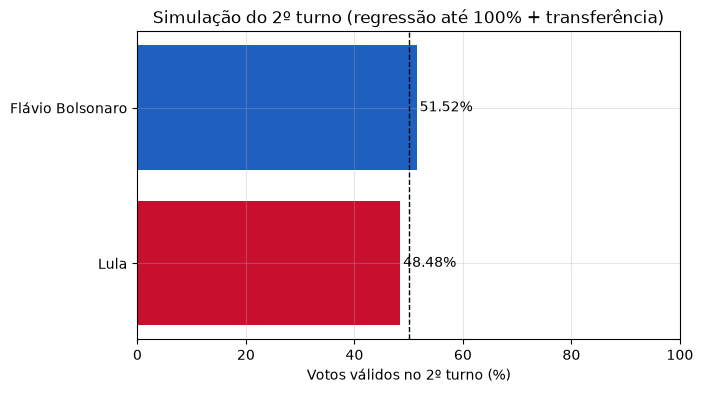

In [91]:
_, _, p_f_reg, p_l_reg = simular_2turno(prev["Flávio Bolsonaro"], prev["Lula"], prev[list(GRUPOS)].to_dict())

print(f"2º turno previsto pela regressão (treino até {CORTE_TREINO}%):")
print(f"  Flávio Bolsonaro: {p_f_reg:.2f}%")
print(f"  Lula:             {p_l_reg:.2f}%")
print(f"Com o resultado real do 1º turno (11.3): Flávio {p_f:.2f}% × Lula {p_l:.2f}%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(["Lula", "Flávio Bolsonaro"], [p_l_reg, p_f_reg], color=[CORES["Lula"], CORES["Flávio Bolsonaro"]])
ax.axvline(50, color="black", ls="--", lw=1)
for i, v in enumerate([p_l_reg, p_f_reg]):
    ax.text(v + 0.5, i, f"{v:.2f}%", va="center")
ax.set_xlim(0, 100)
ax.set_xlabel("Votos válidos no 2º turno (%)")
ax.set_title(f"Simulação do 2º turno (regressão até {CORTE_TREINO}% + transferência)")
plt.show()

**Observações sobre a predição**

- O resultado depende muito mais da **tabela de transferência** do que da regressão: com 50/50 para todos, os blocos da 3ª via se dividem igualmente e a diferença do 1º turno é praticamente mantida. Vale testar cenários, por exemplo transferências baseadas em pesquisas de 2º turno ou no perfil ideológico de cada candidato.
- Os blocos da 3ª via são pequenos e quase estáveis ao longo da apuração, então as retas deles têm inclinação próxima de zero. A regressão faz mais diferença quando `CORTE_TREINO` é baixo, e aí herda os mesmos problemas de extrapolação vistos no capítulo 8.
- O modelo supõe que quem votou em Flávio ou Lula repete o voto e que o comparecimento é igual ao do 1º turno.